# 02 · Huấn luyện HMM-GMM (up, down, left, right) với hmmlearn

1. Tiền xử lý dùng chung: endpoint → MFCC 13 + Δ + ΔΔ → CMVN theo câu.
2. Chia **theo người nói** (danh sách chính thức của dataset, có kiểm tra không trùng người).
3. Mỗi từ một `GMMHMM` **left-to-right**, Gaussian đường chéo, **toàn bộ dữ liệu train**.
4. Khởi tạo bằng **phân đoạn đều** → EM → **khởi tạo lại bằng Viterbi** (chỉ nhận nếu log-likelihood trên validation tốt hơn).
5. Mô hình nền (filler) + ngưỡng từ chối + hiệu chuẩn xác suất, chọn trên validation.

Trước khi huấn luyện, chạy `python tools/check_hmmlearn.py` một lần để chắc hmmlearn trên máy bạn giữ đúng các thiết lập trên.
Tăng log-likelihood **không** bảo đảm tăng độ chính xác nên ta theo dõi cả log-likelihood trên validation và accuracy trên validation.

In [4]:
import os, sys, pathlib, warnings, time
p = pathlib.Path.cwd().resolve()
ROOT = next((c for c in [p, *p.parents] if (c / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook từ bên trong thư mục dự án (nơi có config.py).")
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import matplotlib.pyplot as plt
import joblib
from config import Config, TARGET_WORDS
from speech import dataset as ds
from speech.features import utterance_features
from speech.plots import setup_style
setup_style()

cfg = Config()
N_JOBS = min(4, os.cpu_count() or 1)
print("Thư mục dự án :", ROOT)
print("Dữ liệu gốc   :", cfg.data.data_root)

import copy, datetime
from speech.hmm import train_all, train_filler, filler_loglik, save_bundle
from speech.evaluate import score_matrix, roc_auc, choose_threshold, fit_temperature
from speech.plots import plot_learning_curves, plot_det

Thư mục dự án : D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj
Dữ liệu gốc   : D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj\data\speech_commands_v0.02


In [5]:
# Tải dữ liệu (~2.3 GB) nếu chưa có. Trên Colab nên để dữ liệu ở đĩa cục bộ (/content), không để trên Drive.
if not (pathlib.Path(cfg.data.data_root) / "testing_list.txt").exists():
    ds.download_speech_commands(cfg.data.data_root, cfg.data.url)

## 1. Đặc trưng (có cache)

In [6]:
data = ds.build_feature_sets(cfg, n_jobs=N_JOBS)
train_by_word = {w: data["sets"]["train"][w] for w in TARGET_WORDS}
val_by_word   = {w: data["sets"]["val"][w]   for w in TARGET_WORDS}
print(f"{'từ':>7} {'train':>7} {'val':>6} {'test':>6}   bị endpoint loại (train)")
for w in TARGET_WORDS:
    st = data["stats"][("train", w)]
    print(f"{w:>7} {len(train_by_word[w]):>7} {len(val_by_word[w]):>6} {len(data['sets']['test'][w]):>6}   {st['total'] - st['kept']}/{st['total']}")
val_seqs = [np.asarray(x, np.float64) for w in TARGET_WORDS for x in val_by_word[w]]
val_y = np.array([i for i, w in enumerate(TARGET_WORDS) for _ in val_by_word[w]])

Nạp cache đặc trưng: D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj\cache\features_b8aed20c08_150_600.joblib
     từ   train    val   test   bị endpoint loại (train)
     up    2898    346    421   50/2948
   down    3080    373    405   54/3134
   left    3004    348    411   33/3037
  right    2988    361    395   31/3019


## 2. (Tuỳ chọn) Chọn số trạng thái N và số Gaussian M trên validation

Chỉ dùng **validation**. Lịch huấn luyện ở đây ngắn để chạy nhanh. Đặt `RUN_GRID = False` để dùng giá trị mặc định trong `config.py`.

In [9]:
RUN_GRID = True
grid = []
if RUN_GRID:
    for N in [4, 6, 8]:
        for M in [2, 4]:
            c = copy.deepcopy(cfg)
            c.model.n_states = {w: N for w in TARGET_WORDS}
            c.model.n_mix, c.model.n_iter, c.model.realign_rounds = M, 5, 0
            t0 = time.time()
            m_, _ = train_all(train_by_word, val_by_word, c, n_jobs=N_JOBS)
            acc = float(np.mean(score_matrix(m_, val_seqs).argmax(1) == val_y))
            grid.append((N, M, acc))
            print(f"N={N} M={M}  val acc = {acc:.4f}   ({time.time()-t0:.0f}s)", flush=True)
    best = max(grid, key=lambda r: r[2])
    print("Chọn:", best)
    cfg.model.n_states = {w: best[0] for w in TARGET_WORDS}
    cfg.model.n_mix = best[1]
print("n_states =", cfg.model.n_states, "| n_mix =", cfg.model.n_mix)

N=4 M=2  val acc = 0.9727   (97s)
N=4 M=4  val acc = 0.9769   (117s)
N=6 M=2  val acc = 0.9762   (140s)
N=6 M=4  val acc = 0.9804   (166s)
N=8 M=2  val acc = 0.9804   (152s)
N=8 M=4  val acc = 0.9832   (174s)
Chọn: (8, 4, 0.9831932773109243)
n_states = {'up': 8, 'down': 8, 'left': 8, 'right': 8} | n_mix = 4


## 3. Huấn luyện chính thức

In [10]:
print("n_iter =", cfg.model.n_iter)

n_iter = 12


Huấn luyện xong sau 1492 s
    up: val LL/khung tốt nhất theo lần khởi tạo = v0: -49.116, v1: -49.063, v2: -49.029
  down: val LL/khung tốt nhất theo lần khởi tạo = v0: -46.558, v1: -46.464, v2: -46.452
  left: val LL/khung tốt nhất theo lần khởi tạo = v0: -48.852, v1: -48.783, v2: -48.766
 right: val LL/khung tốt nhất theo lần khởi tạo = v0: -47.447, v1: -47.387, v2: -47.359
Độ chính xác validation (4 lớp): 0.9866946778711485


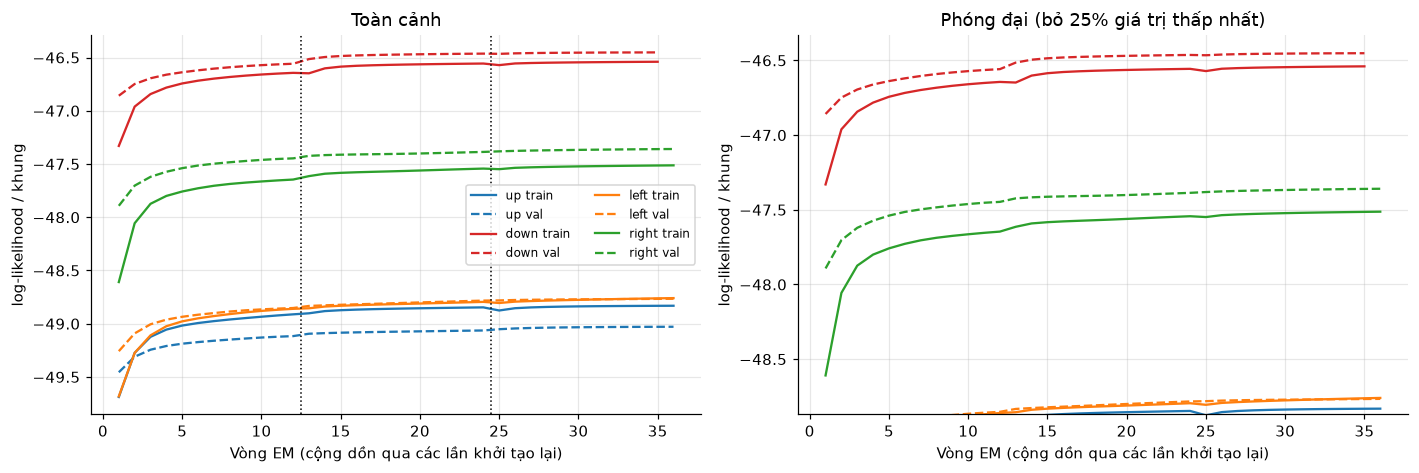

In [11]:
t0 = time.time()
models, history = train_all(train_by_word, val_by_word, cfg, n_jobs=N_JOBS)
print(f"Huấn luyện xong sau {time.time()-t0:.0f} s")
for w in TARGET_WORDS:
    h = [r for r in history if r["word"] == w]
    print(f"{w:>6}: val LL/khung tốt nhất theo lần khởi tạo = " +
          ", ".join(f"v{r}: {max(x['val_ll'] for x in h if x['round'] == r):.3f}" for r in sorted({x['round'] for x in h})))
S_val = score_matrix(models, val_seqs)
print("Độ chính xác validation (4 lớp):", np.mean(S_val.argmax(1) == val_y))
plot_learning_curves(history, TARGET_WORDS); plt.show()

**Cách đọc:** nét liền = train, nét đứt = validation (người nói chưa thấy); đường dọc đen = bắt đầu một lần khởi tạo lại bằng Viterbi.
Nếu val ngừng tăng trong khi train vẫn tăng nghĩa là bắt đầu quá khớp; vòng tốt nhất theo val đã được giữ lại.

## 4. Mô hình nền, ngưỡng từ chối, hiệu chuẩn xác suất

- **Filler**: GMM trên khung của "từ khác" + nhiễu nền. Điểm từ chối: `LLR/khung = (LL từ thắng − LL filler) / số khung`. Số Gaussian chọn theo AUC trên validation.
- **Ngưỡng** ưu tiên **không bỏ sót từ đúng** (chỉ từ chối ~3% từ nhận đúng, nhiễu nền lọt qua tối đa ~1%).
- **Temperature scaling**: tổng log-likelihood HMM bị "thổi phồng" nên softmax thô luôn ≈ 1; chia cho `tau` (khớp trên validation) để có xác suất đọc được.

filler   8 Gaussian: AUC = 0.9378
filler  16 Gaussian: AUC = 0.9440
filler  32 Gaussian: AUC = 0.9483
filler  64 Gaussian: AUC = 0.9536
Chọn filler 64 Gaussian | ngưỡng LLR/khung = -0.552 | tau = 20.0
  chấp nhận từ đúng: 96.9% | nhận nhầm từ khác: 47.8% | nhận nhầm nhiễu: 0.0%


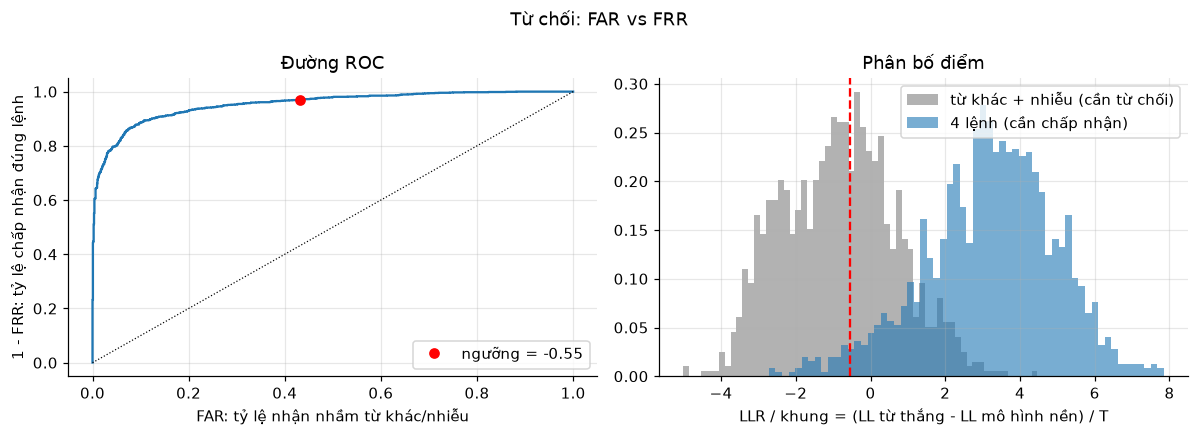

In [12]:
filler_train = list(data["unknown"]["train"]) + list(data["noise"]["train"])
unk_val = [np.asarray(x, np.float64) for x in data["unknown"]["val"]]
noi_val = [np.asarray(x, np.float64) for x in data["noise"]["val"]]
S_unk, S_noi = score_matrix(models, unk_val), score_matrix(models, noi_val)
T = lambda seqs: np.array([len(s) for s in seqs])
correct = S_val.argmax(1) == val_y
pos_seqs = [s for s, ok in zip(val_seqs, correct) if ok]

def llr(S, seqs, f):
    return (S.max(axis=1) - filler_loglik(f, seqs)) / T(seqs)

best = (-1.0, None, None)
for M in [8, 16, 32, 64]:
    f_ = train_filler(filler_train, M, cfg.model.seed)
    auc = roc_auc(llr(S_val[correct], pos_seqs, f_),
                  np.concatenate([llr(S_unk, unk_val, f_), llr(S_noi, noi_val, f_)]))
    print(f"filler {M:>3} Gaussian: AUC = {auc:.4f}")
    if auc > best[0]:
        best = (auc, M, f_)
filler = best[2]; cfg.model.filler_mix = best[1]

pos_llr, unk_llr, noi_llr = llr(S_val[correct], pos_seqs, filler), llr(S_unk, unk_val, filler), llr(S_noi, noi_val, filler)
TARGET_FRR, NOISE_FAR = 0.03, 0.01
thr_llr = choose_threshold(pos_llr, noi_llr, TARGET_FRR, NOISE_FAR)
tau = fit_temperature(S_val, val_y)
print(f"Chọn filler {best[1]} Gaussian | ngưỡng LLR/khung = {thr_llr:.3f} | tau = {tau:.1f}")
print(f"  chấp nhận từ đúng: {np.mean(pos_llr >= thr_llr):.1%} | nhận nhầm từ khác: {np.mean(unk_llr >= thr_llr):.1%} | nhận nhầm nhiễu: {np.mean(noi_llr >= thr_llr):.1%}")
plot_det(pos_llr, np.concatenate([unk_llr, noi_llr]), thr_llr); plt.show()

## 5. Lưu mô hình (cấu hình tiền xử lý được lưu kèm)

In [13]:
out = pathlib.Path(cfg.data.weights_dir) / "hmm_gmm_speech_models.pkl"
meta = dict(date=datetime.datetime.now().isoformat(timespec="seconds"),
            n_train={w: len(train_by_word[w]) for w in TARGET_WORDS}, grid=grid)
save_bundle(out, cfg, models, filler, dict(min_llr_per_frame=float(thr_llr), temperature=float(tau)), meta)
print("Đã lưu:", out)

Đã lưu: D:\2027\HTTM\speech_hmm_project_v4_hmmlearn\proj\weight\hmm_gmm_speech_models.pkl
